Image loaded successfully!


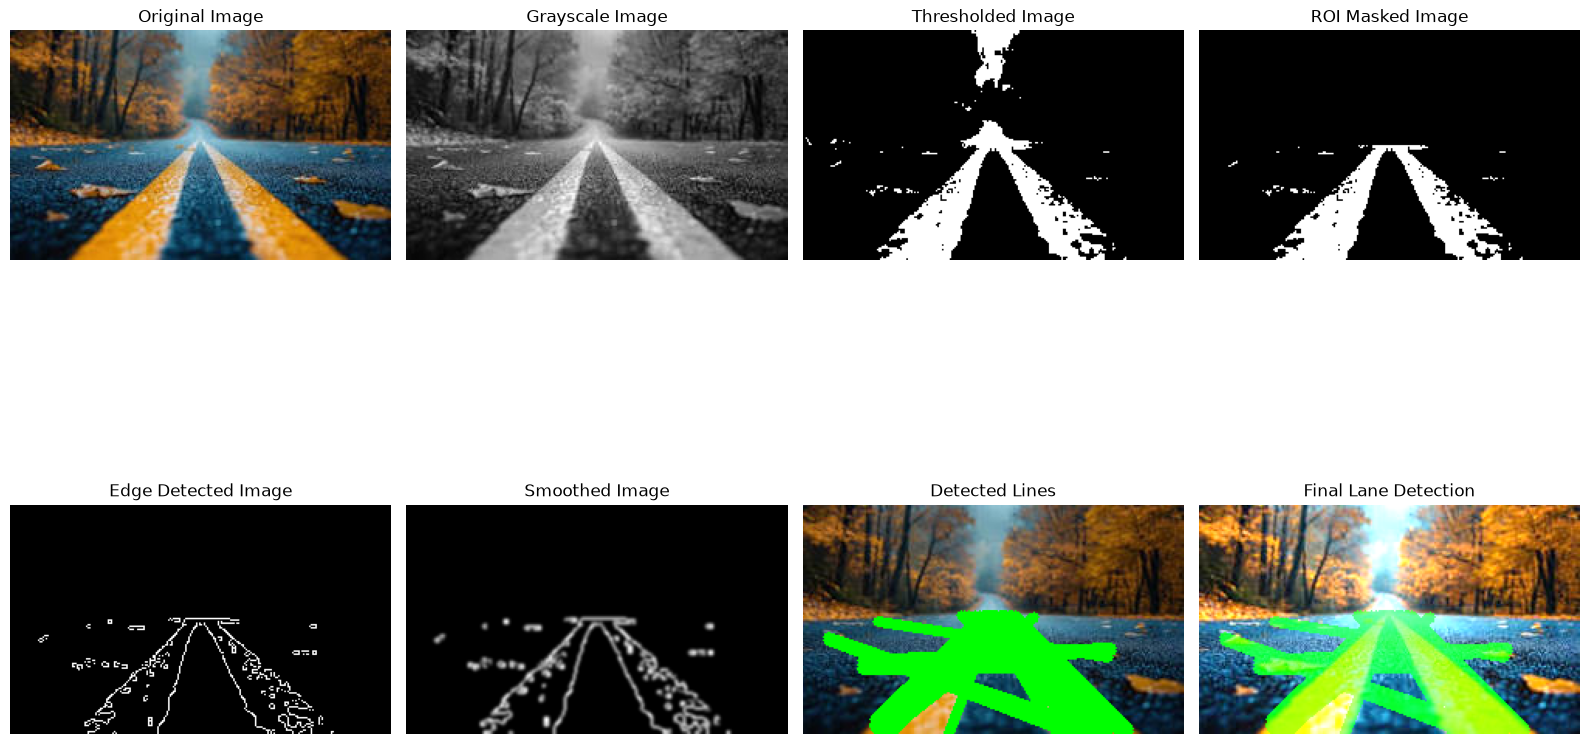

Lane Detection Completed Successfully!


In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Step 1: Read Original Image
image = cv2.imread('road.jpg')

if image is None:
    print("Image not found! Check the image path.")

else:
    print("Image loaded successfully!")

    # Step 2: Convert to Grayscale
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    # Step 3: Apply Thresholding
    ret, threshold = cv2.threshold(
        gray, 150, 255, cv2.THRESH_BINARY
    )

    # Step 4: Region of Interest (ROI) Masking
    height, width = gray.shape

    mask = np.zeros_like(gray)

    polygon = np.array([[
        (0, height),
        (width, height),
        (width // 2 + 100, height // 2),
        (width // 2 - 100, height // 2)
    ]], dtype=np.int32)

    cv2.fillPoly(mask, polygon, 255)

    roi = cv2.bitwise_and(threshold, mask)

    # Step 5: Edge Detection using Canny
    edges = cv2.Canny(roi, 50, 150)

    # Step 6: Gaussian Blur
    blur = cv2.GaussianBlur(edges, (5, 5), 0)

    # Step 7: Detect Lines using Hough Transform
    lines = cv2.HoughLinesP(
        blur,
        rho=1,
        theta=np.pi / 180,
        threshold=50,
        minLineLength=50,
        maxLineGap=100
    )

    # Draw detected lines
    line_image = image.copy()

    if lines is not None:

        for line in lines:

            # FIX: Reshape line coordinates
            x1, y1, x2, y2 = np.asarray(line).reshape(-1)[:4]

            cv2.line(
                line_image,
                (int(x1), int(y1)),
                (int(x2), int(y2)),
                (0, 255, 0),
                5
            )

    else:
        print("No lane lines detected.")

    # Step 8: Final Lane Detection Output
    final_image = cv2.addWeighted(
        image, 0.8,
        line_image, 1.0,
        0
    )

    # Step 9: Display All 8 Outputs
    plt.figure(figsize=(16, 12))

    # 1. Original Image
    plt.subplot(2, 4, 1)
    plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")
    plt.axis("off")

    # 2. Grayscale Image
    plt.subplot(2, 4, 2)
    plt.imshow(gray, cmap='gray')
    plt.title("Grayscale Image")
    plt.axis("off")

    # 3. Thresholded Image
    plt.subplot(2, 4, 3)
    plt.imshow(threshold, cmap='gray')
    plt.title("Thresholded Image")
    plt.axis("off")

    # 4. ROI Masked Image
    plt.subplot(2, 4, 4)
    plt.imshow(roi, cmap='gray')
    plt.title("ROI Masked Image")
    plt.axis("off")

    # 5. Edge Detected Image
    plt.subplot(2, 4, 5)
    plt.imshow(edges, cmap='gray')
    plt.title("Edge Detected Image")
    plt.axis("off")

    # 6. Smoothed Image
    plt.subplot(2, 4, 6)
    plt.imshow(blur, cmap='gray')
    plt.title("Smoothed Image")
    plt.axis("off")

    # 7. Detected Lines
    plt.subplot(2, 4, 7)
    plt.imshow(cv2.cvtColor(line_image, cv2.COLOR_BGR2RGB))
    plt.title("Detected Lines")
    plt.axis("off")

    # 8. Final Lane Detection Output
    plt.subplot(2, 4, 8)
    plt.imshow(cv2.cvtColor(final_image, cv2.COLOR_BGR2RGB))
    plt.title("Final Lane Detection")
    plt.axis("off")

    plt.tight_layout()
    plt.show()

    print("Lane Detection Completed Successfully!")